In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("Client_Service_Financial_Operations_Practice.xlsx")

print(df.head())

  Request_ID Client_ID           Request_Type Priority Date_Received  \
0     REQ001    CL1001        Account Opening     High    2026-10-01   
1     REQ002    CL1002          Fund Purchase   Medium    2026-10-01   
2     REQ003    CL1003         Address Update      Low    2026-10-02   
3     REQ004    CL1004  Insurance Application     High    2026-10-02   
4     REQ005    CL1005        Account Opening     High    2026-10-03   

    Due_Date Date_Completed     Status    Advisor Documentation_Complete  \
0 2026-10-03     2026-10-02  Completed  Advisor A                    Yes   
1 2026-10-04     2026-10-05  Completed  Advisor B                    Yes   
2 2026-10-06     2026-10-03  Completed  Advisor A                    Yes   
3 2026-10-05            NaT    Pending  Advisor C                     No   
4 2026-10-05     2026-10-04  Completed  Advisor B                    Yes   

   Transaction_Amount_INR Follow_Up_Required  
0                       0                 No  
1               

In [2]:
df["Date_Received"] = pd.to_datetime(df["Date_Received"])
df["Due_Date"] = pd.to_datetime(df["Due_Date"])
df["Date_Completed"] = pd.to_datetime(df["Date_Completed"])

df["Turnaround_Days"] = (
    df["Date_Completed"] - df["Date_Received"]
).dt.days

print(df.isnull().sum())

Request_ID                 0
Client_ID                  0
Request_Type               0
Priority                   0
Date_Received              0
Due_Date                   0
Date_Completed            10
Status                     0
Advisor                    0
Documentation_Complete     0
Transaction_Amount_INR     0
Follow_Up_Required         0
Turnaround_Days           10
dtype: int64


In [3]:
total_requests = len(df)

completed = (df["Status"] == "Completed").sum()

pending = (df["Status"] == "Pending").sum()

in_progress = (df["Status"] == "In Progress").sum()

documentation_gaps = (
    df["Documentation_Complete"] == "No"
).sum()

follow_ups = (
    df["Follow_Up_Required"] == "Yes"
).sum()

completed_df = df[df["Status"] == "Completed"]

on_time = (
    completed_df["Date_Completed"] <= completed_df["Due_Date"]
).mean() * 100

avg_turnaround = completed_df["Turnaround_Days"].mean()

print("Total Requests:", total_requests)
print("Completed:", completed)
print("Pending:", pending)
print("In Progress:", in_progress)
print("Documentation Gaps:", documentation_gaps)
print("Follow-ups Required:", follow_ups)
print("On-time Completion Rate:", round(on_time, 2), "%")
print("Average Turnaround:", round(avg_turnaround, 2), "days")

Total Requests: 30
Completed: 20
Pending: 6
In Progress: 4
Documentation Gaps: 6
Follow-ups Required: 10
On-time Completion Rate: 90.0 %
Average Turnaround: 1.75 days


Request_Type
Fund Purchase            6
Account Opening          5
Insurance Application    4
Withdrawal               4
Address Update           3
Meeting Follow-up        3
Expense Documentation    3
Beneficiary Update       2
Name: count, dtype: int64


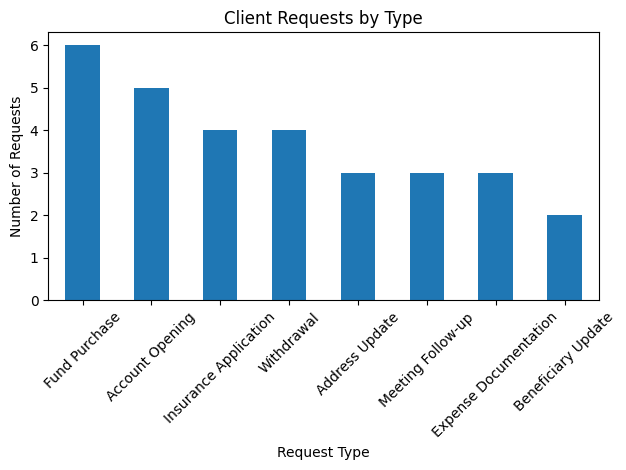

In [4]:
request_summary = df["Request_Type"].value_counts()

print(request_summary)

request_summary.plot(kind="bar")

plt.title("Client Requests by Type")
plt.xlabel("Request Type")
plt.ylabel("Number of Requests")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

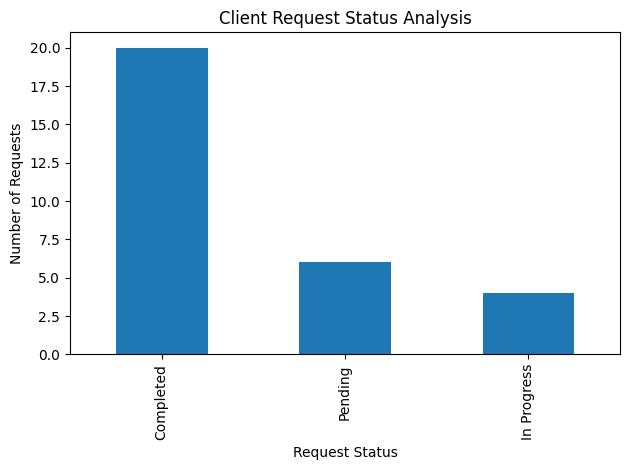

In [6]:
status_summary = df["Status"].value_counts()

status_summary.plot(kind="bar")

plt.title("Client Request Status Analysis")
plt.xlabel("Request Status")
plt.ylabel("Number of Requests")
plt.tight_layout()
plt.show()

In [7]:
summary = pd.DataFrame({
    "KPI": ["Total Requests", "Completed", "Pending",
            "In Progress", "Documentation Gaps",
            "Follow-ups", "On-time Completion (%)",
            "Average Turnaround (Days)"],

    "Value": [total_requests, completed, pending,
              in_progress, documentation_gaps,
              follow_ups, round(on_time, 2),
              round(avg_turnaround, 2)]
})

summary.to_excel("Client_Service_KPI_Summary.xlsx",
                 index=False)

print("KPI Summary Exported Successfully!")

KPI Summary Exported Successfully!
